# Klasifikasi Multilabel: Topik Artikel Ilmiah (arXiv)

**Dataset:** `train.csv` (20.972 artikel), `test.csv` (8.989 artikel tanpa label), dan `sample_submission.csv`.
Tiap artikel punya judul (`TITLE`) dan abstrak (`ABSTRACT`), serta **6 label biner**: *Computer Science, Physics, Mathematics, Statistics, Quantitative Biology, Quantitative Finance*.

**Mengapa multilabel?** Satu artikel boleh memiliki **lebih dari satu topik sekaligus** (misalnya Computer Science dan Statistics), berbeda dengan multikelas yang hanya memilih satu.

**Pertanyaan:**
1. Bagaimana sebaran label dan seberapa sering label muncul bersamaan?
2. Seberapa baik model memprediksi kumpulan topik dari teks?
3. Apakah label langka (Quantitative Biology dan Finance) bisa dikenali?

In [1]:
import glob, os
def cari(nama):
    # cari file di folder ini maupun subfolder
    h = glob.glob('**/'+nama, recursive=True)
    assert h, f"File {nama} tidak ditemukan di {os.getcwd()}"
    return h[0]
from sklearn.metrics import f1_score, hamming_loss, precision_score, recall_score, accuracy_score
def ringkas(Y, P):
    return dict(F1_micro=f1_score(Y,P,average='micro',zero_division=0), F1_macro=f1_score(Y,P,average='macro',zero_division=0),
                F1_samples=f1_score(Y,P,average='samples',zero_division=0), Hamming_loss=hamming_loss(Y,P), Subset_acc=accuracy_score(Y,P))
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import train_test_split
sns.set_theme(style='whitegrid')
tr = pd.read_csv(cari('train.csv')); te = pd.read_csv(cari('test.csv'))
LAB = ['Computer Science','Physics','Mathematics','Statistics','Quantitative Biology','Quantitative Finance']
print(tr.shape, te.shape); tr[['TITLE']+LAB].head()

(20972, 9) (8989, 3)


,TITLE,Computer Science,Physics,Mathematics,Statistics,Quantitative Biology,Quantitative Finance
0,Reconstructing Subject-Specific Effect Maps,1,0,0,0,0,0
1,Rotation Invariance Neural Network,1,0,0,0,0,0
2,Spherical polyharmonics and Poisson kernels fo...,0,0,1,0,0,0
3,A finite element approximation for the stochas...,0,0,1,0,0,0
4,Comparative study of Discrete Wavelet Transfor...,1,0,0,1,0,0


## 1. Pemahaman Data

Missing value: 0 | ID duplikat: 0
Computer Science        40.98 %
Physics                 28.67 %
Mathematics             26.79 %
Statistics              24.82 %
Quantitative Biology      2.8 %
Quantitative Finance     1.19 %
dtype: str


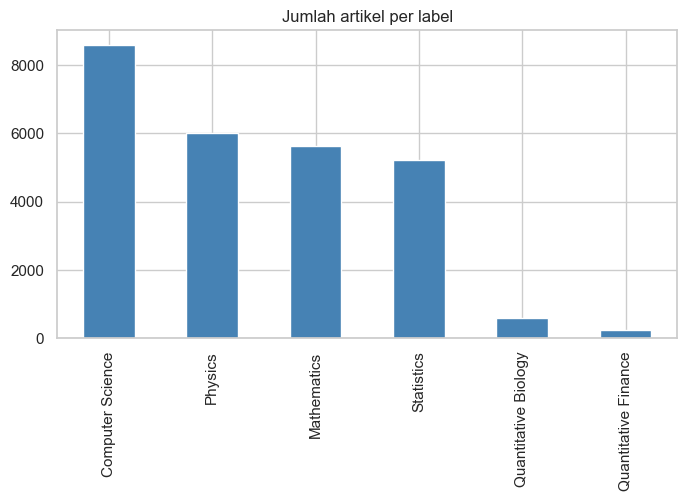


Jumlah label per artikel:
1    15928
2     4793
3      251
Name: count, dtype: int64


In [2]:
print('Missing value:', tr[['TITLE','ABSTRACT']+LAB].isna().sum().sum(), '| ID duplikat:', tr.ID.duplicated().sum())
jumlah = tr[LAB].sum().sort_values(ascending=False)
print((jumlah/len(tr)*100).round(2).astype(str)+' %'); 
jumlah.plot.bar(figsize=(8,4), color='steelblue', title='Jumlah artikel per label'); plt.show()
print('\nJumlah label per artikel:'); print(tr[LAB].sum(axis=1).value_counts().sort_index())

**Temuan:**
- Label sangat **tidak seimbang**: *Computer Science* sekitar 41% artikel, sedangkan *Quantitative Finance* hanya sekitar 1,2% dan *Quantitative Biology* sekitar 2,8%.
- Mayoritas artikel (± 76%) hanya punya **1 label**, ± 23% punya **2 label**, dan ± 1% punya 3 label. Tidak ada artikel tanpa label.
- Karena label langka, *accuracy* per label menyesatkan. Metrik yang dipakai: **F1-micro** (menimbang tiap prediksi), **F1-macro** (semua label bobot sama), dan **Hamming loss** (proporsi salah per label).

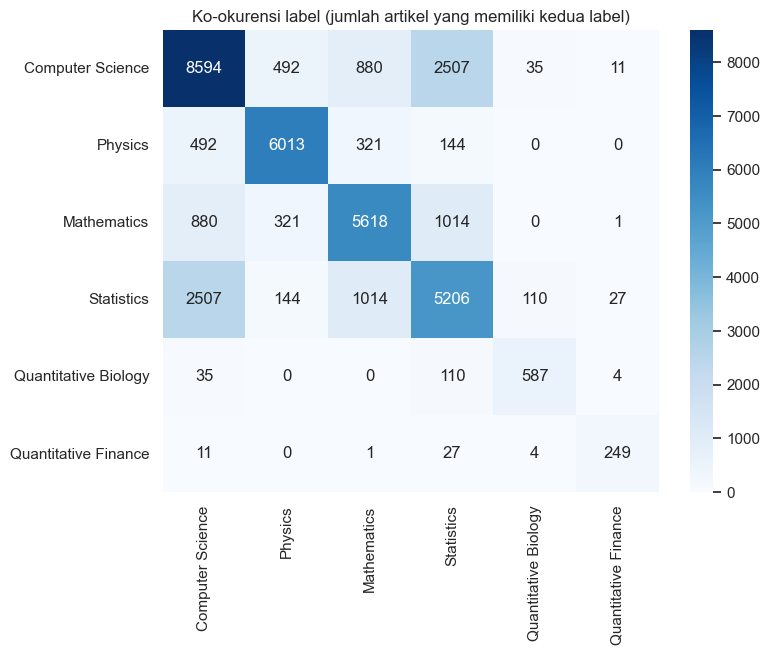

,Computer Science,Physics,Mathematics,Statistics,Quantitative Biology,Quantitative Finance
Computer Science,1.00,-0.42,-0.31,0.08,-0.12,-0.08
Physics,-0.42,1.00,-0.31,-0.33,-0.11,-0.07
Mathematics,-0.31,-0.31,1.00,-0.09,-0.10,-0.07
Statistics,0.08,-0.33,-0.09,1.00,-0.02,-0.04
Quantitative Biology,-0.12,-0.11,-0.10,-0.02,1.00,-0.01
Quantitative Finance,-0.08,-0.07,-0.07,-0.04,-0.01,1.00


In [3]:
co = tr[LAB].T.dot(tr[LAB])
plt.figure(figsize=(8,6)); sns.heatmap(co, annot=True, fmt='d', cmap='Blues'); plt.title('Ko-okurensi label (jumlah artikel yang memiliki kedua label)'); plt.show()
korel = tr[LAB].corr().round(2); korel

**Cara membaca:** angka di luar diagonal menunjukkan berapa artikel memiliki dua label sekaligus. Pasangan yang sering muncul bersama (misalnya Computer Science dengan Statistics, atau Mathematics dengan Statistics) menunjukkan bahwa label **tidak saling lepas**, sehingga model multilabel memang tepat dipakai.

In [4]:
tr['teks'] = tr.TITLE.str.strip()+'. '+tr.ABSTRACT.str.replace(r'\s+',' ',regex=True).str.strip()
te['teks'] = te.TITLE.str.strip()+'. '+te.ABSTRACT.str.replace(r'\s+',' ',regex=True).str.strip()
print('Panjang teks (kata), ringkasan:'); print(tr.teks.str.split().str.len().describe().round(0))

Panjang teks (kata), ringkasan:
count    20972.0
mean       158.0
std         61.0
min          5.0
25%        113.0
50%        154.0
75%        200.0
max        462.0
Name: teks, dtype: float64


## 2. Pra-pemrosesan dan Pembagian Data

In [5]:
Y = tr[LAB].values
Xt_tr, Xt_tmp, Y_tr, Y_tmp = train_test_split(tr.teks, Y, test_size=0.3, random_state=42)
Xt_va, Xt_te, Y_va, Y_te = train_test_split(Xt_tmp, Y_tmp, test_size=0.5, random_state=42)
print('train/val/test:', len(Xt_tr), len(Xt_va), len(Xt_te))
tfidf = TfidfVectorizer(stop_words='english', ngram_range=(1,2), min_df=3, max_features=80000, sublinear_tf=True)
A_tr = tfidf.fit_transform(Xt_tr); A_va = tfidf.transform(Xt_va); A_te = tfidf.transform(Xt_te)
print('Ukuran fitur TF-IDF:', A_tr.shape)

train/val/test: 14680 3146 3146
Ukuran fitur TF-IDF: (14680, 74708)


Data dibagi **70% latih, 15% validasi, 15% uji**. File `test.csv` asli tidak punya label, jadi dipakai hanya untuk prediksi akhir. Teks diubah menjadi vektor **TF-IDF** (kata tunggal dan pasangan kata). Pembagian dilakukan **sebelum** TF-IDF dipelajari agar tidak ada kebocoran dari data validasi/uji.

## 3. Pemodelan (One-vs-Rest)

In [6]:
models = {
 'Logistic Regression': OneVsRestClassifier(LogisticRegression(C=10, max_iter=1000)),
 'Logistic Regression (balanced)': OneVsRestClassifier(LogisticRegression(C=10, max_iter=1000, class_weight='balanced')),
 'Linear SVM': OneVsRestClassifier(LinearSVC(C=0.5)),
}
skor, prob = {}, {}
for n,m in models.items():
    m.fit(A_tr, Y_tr)
    prob[n] = m.decision_function(A_va)
    skor[n] = ringkas(Y_va, (prob[n]>0).astype(int))
pd.DataFrame(skor).T.round(4)

,F1_micro,F1_macro,F1_samples,Hamming_loss,Subset_acc
Logistic Regression,0.8198,0.6545,0.8141,0.0723,0.6732
Logistic Regression (balanced),0.8328,0.7725,0.8409,0.0710,0.6736
Linear SVM,0.8216,0.6451,0.8149,0.0714,0.6777


**Cara membaca:** *Subset accuracy* sangat ketat karena **semua** label artikel harus benar, sehingga lebih rendah dibanding F1. *Hamming loss* semakin kecil semakin baik.

**Temuan:** pembobotan `class_weight='balanced'` menaikkan **F1-macro dari ± 0,65 menjadi ± 0,77** dengan F1-micro tetap sekitar 0,82-0,83, artinya manfaatnya terutama pada label langka. Karena itu versi *balanced* dipilih.

In [7]:
# Tuning ambang keputusan per label pada data validasi (untuk meningkatkan F1 label langka)
nama = 'Logistic Regression (balanced)'
S_va = prob[nama]
thr = []
for j in range(len(LAB)):
    kandidat = np.linspace(S_va[:,j].min(), S_va[:,j].max(), 200)
    f = [f1_score(Y_va[:,j], (S_va[:,j]>t).astype(int), zero_division=0) for t in kandidat]
    thr.append(kandidat[int(np.argmax(f))])
thr = np.array(thr)
S_te = models[nama].decision_function(A_te)
hasil = pd.DataFrame({'ambang 0 (bawaan)': ringkas(Y_te,(S_te>0).astype(int)),
                      'ambang per label (tuning)': ringkas(Y_te,(S_te>thr).astype(int))}).T
hasil.round(4)

,F1_micro,F1_macro,F1_samples,Hamming_loss,Subset_acc
ambang 0 (bawaan),0.8269,0.7716,0.8347,0.0746,0.6564
ambang per label (tuning),0.8243,0.7637,0.8332,0.0763,0.6516


In [8]:
P = (S_te>0).astype(int)
dfp = pd.DataFrame({'label':LAB,'jumlah_di_uji':Y_te.sum(0),
    'precision':precision_score(Y_te,P,average=None,zero_division=0),
    'recall':recall_score(Y_te,P,average=None,zero_division=0),
    'F1':f1_score(Y_te,P,average=None,zero_division=0)}).set_index('label')
dfp.round(3)

,jumlah_di_uji,precision,recall,F1
label,,,,
Computer Science,1299,0.812,0.873,0.841
Physics,912,0.876,0.875,0.875
Mathematics,854,0.806,0.820,0.813
Statistics,793,0.757,0.834,0.794
Quantitative Biology,94,0.642,0.553,0.594
Quantitative Finance,29,0.700,0.724,0.712


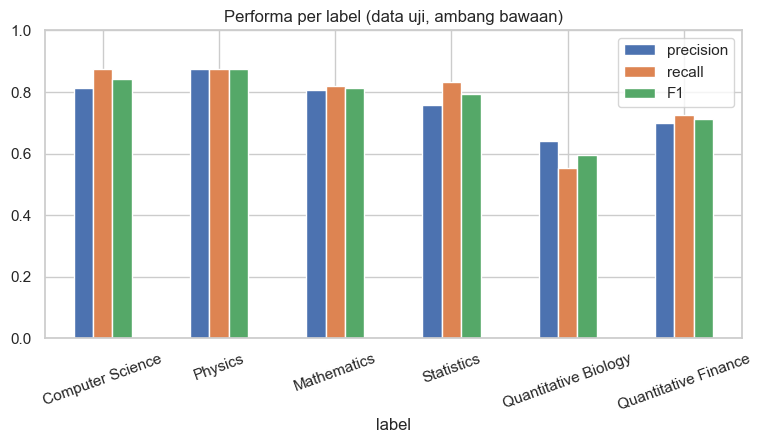

In [9]:
dfp[['precision','recall','F1']].plot.bar(figsize=(9,4), title='Performa per label (data uji, ambang bawaan)'); plt.ylim(0,1); plt.xticks(rotation=20); plt.show()

**Temuan:**
- **Tuning ambang per label tidak membantu** pada data uji (F1-macro ± 0,764 vs ± 0,772 dengan ambang bawaan). Penyebabnya kemungkinan *overfitting* ambang pada data validasi yang kecil: label *Quantitative Finance* hanya punya puluhan contoh positif sehingga ambang terbaik di validasi tidak stabil. Karena itu **ambang bawaan (0)** dipakai untuk hasil akhir.
- Label besar (*Physics* F1 ± 0,88, *Computer Science* ± 0,84, *Mathematics* ± 0,81, *Statistics* ± 0,79) dikenali baik. Label langka lebih sulit: *Quantitative Biology* F1 ± 0,59 (recall hanya ± 0,55, lebih dari separuh artikelnya terlewat) dan *Quantitative Finance* ± 0,71. Dengan hanya 29 contoh uji untuk Finance, angka ini kurang stabil.

In [10]:
# Contoh prediksi
idx = np.random.RandomState(1).choice(len(Xt_te), 5, replace=False)
for i in idx:
    asli = [l for l,v in zip(LAB, Y_te[i]) if v]; pred = [l for l,v in zip(LAB, P[i]) if v]
    print('Teks   :', Xt_te.iloc[i][:110].replace('\n',' '),'...'); print('Asli   :', asli); print('Prediksi:', pred, '\n')

Teks   : A Benchmark on Reliability of Complex Discrete Systems: Emergency Power Supply of a Nuclear Power Plant. This  ...
Asli   : ['Computer Science']
Prediksi: ['Computer Science'] 

Teks   : Optimal Rates of Sketched-regularized Algorithms for Least-Squares Regression over Hilbert Spaces. We investig ...
Asli   : ['Statistics']
Prediksi: ['Mathematics', 'Statistics'] 

Teks   : Reliable counting of weakly labeled concepts by a single spiking neuron model. Making an informed, correct and ...
Asli   : ['Quantitative Biology']
Prediksi: ['Computer Science', 'Statistics', 'Quantitative Biology'] 

Teks   : A spectral/hp element MHD solver. A new MHD solver, based on the Nektar++ spectral/hp element framework, is pr ...
Asli   : ['Physics']
Prediksi: ['Computer Science', 'Physics'] 

Teks   : An evolutionary strategy for DeltaE - E identification. In this article we present an automatic method for cha ...
Asli   : ['Computer Science', 'Physics']
Prediksi: [] 



## 4. Prediksi pada `test.csv` (tanpa label)

In [11]:
# latih ulang pada seluruh data berlabel, lalu prediksi file test
tfidf_f = TfidfVectorizer(stop_words='english', ngram_range=(1,2), min_df=3, max_features=80000, sublinear_tf=True)
A_all = tfidf_f.fit_transform(tr.teks); A_test = tfidf_f.transform(te.teks)
final = OneVsRestClassifier(LogisticRegression(C=10, max_iter=1000, class_weight='balanced')).fit(A_all, Y)
Pt = (final.decision_function(A_test) > 0).astype(int)
sub = pd.DataFrame(Pt, columns=LAB); sub.insert(0,'ID',te.ID.values)
sub.to_csv('prediksi_arxiv.csv', index=False)
print(sub.shape); print((sub[LAB].mean()*100).round(2).astype(str)+' %  (proporsi prediksi positif per label)')
print('Proporsi label di data latih:'); print((tr[LAB].mean()*100).round(2).astype(str)+' %')

(8989, 7)
Computer Science        43.91 %  (proporsi prediksi positif per label)
Physics                 28.96 %  (proporsi prediksi positif per label)
Mathematics             27.43 %  (proporsi prediksi positif per label)
Statistics              27.17 %  (proporsi prediksi positif per label)
Quantitative Biology      2.9 %  (proporsi prediksi positif per label)
Quantitative Finance     1.27 %  (proporsi prediksi positif per label)
dtype: str
Proporsi label di data latih:
Computer Science        40.98 %
Physics                 28.67 %
Mathematics             26.79 %
Statistics              24.82 %
Quantitative Biology      2.8 %
Quantitative Finance     1.19 %
dtype: str


## 5. Kesimpulan
- Ini kasus **multilabel**: satu artikel dapat memiliki beberapa topik; ± 24% artikel memiliki lebih dari satu label.
- Label sangat timpang (Computer Science ± 41% vs Quantitative Finance ± 1,2%), sehingga metrik yang sesuai adalah **F1-micro/macro** dan **Hamming loss**, bukan akurasi per sampel.
- Model **TF-IDF + One-vs-Rest Logistic Regression** (`class_weight='balanced'`) menjadi baseline yang kuat: F1-micro ± 0,83, F1-macro ± 0,77, Hamming loss ± 0,07. Pembobotan kelas menaikkan F1-macro dari ± 0,65 ke ± 0,77, sedangkan **tuning ambang per label tidak memberi tambahan** (cenderung overfit pada validasi).
- Label langka tetap lebih lemah (F1 ± 0,59 untuk Quantitative Biology dan ± 0,71 untuk Quantitative Finance) dibanding label besar (± 0,79-0,88).
- *Subset accuracy* (± 0,66) jauh lebih rendah daripada F1 karena sangat ketat (semua label harus tepat).
- Hasil prediksi untuk `test.csv` disimpan di `prediksi_arxiv.csv` dengan format yang sama seperti `sample_submission.csv`. Karena label test tidak tersedia, kualitasnya tidak dapat dipastikan langsung. Sebagai pemeriksaan kasar, proporsi prediksi positif per label dibandingkan dengan proporsi di data latih (hasilnya cukup berdekatan).
- **Langkah lanjutan:** *Classifier Chains* untuk menangkap hubungan antarlabel, atau model bahasa (misalnya BERT/SciBERT) yang biasanya lebih unggul pada teks ilmiah.